In [2]:
#Parse MUMmer pk vs pv alignment and find positions of snps in each species 

import pandas as pd

pv_snps = pd.read_csv('PK_vs_PV.snps', sep='\t', skiprows=4,
                       names=['Pk_pos', 'Pk_base', 'Pv_base', 'Pv_pos', 'buff', 'dist', 'frame_1', 'frame_2', 'contig', 'tag'])

In [3]:
legit_locs = ['PKNH_01_v2', 'PKNH_02_v2', 'PKNH_03_v2', 'PKNH_04_v2', 'PKNH_05_v2', 'PKNH_06_v2', 'PKNH_07_v2', 'PKNH_08_v2', 'PKNH_09_v2', 'PKNH_10_v2', 'PKNH_11_v2', 'PKNH_12_v2', 'PKNH_13_v2', 'PKNH_14_v2', 'PKNH_API_v2', 'PKNH_MIT_v2']
pv_snps_leg = pv_snps.loc[pv_snps['contig'].isin(legit_locs)]

In [4]:
pv_snps_match = pv_snps_leg.loc[pv_snps_leg['contig'].str[-6:]==pv_snps_leg['tag'].str[-6:]]

In [5]:
pv_snps_match['Pk_seqid_short'] = pv_snps_match['contig'].str[:7]
pv_snps_match.tail()

/tmp/ipykernel_41/3256358226.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pv_snps_match['Pk_seqid_short'] = pv_snps_match['contig'].str[:7]


,Pk_pos,Pk_base,Pv_base,Pv_pos,buff,dist,frame_1,frame_2,contig,tag,Pk_seqid_short
855642,5329,T,G,632,13,629,1,1,PKNH_MIT_v2,PvP01_MIT_v2,PKNH_MI
855643,5515,T,C,818,186,443,1,1,PKNH_MIT_v2,PvP01_MIT_v2,PKNH_MI
855644,5801,T,C,1104,9,157,1,1,PKNH_MIT_v2,PvP01_MIT_v2,PKNH_MI
855645,5810,A,G,1113,9,148,1,1,PKNH_MIT_v2,PvP01_MIT_v2,PKNH_MI
855646,5954,T,A,1257,4,4,1,1,PKNH_MIT_v2,PvP01_MIT_v2,PKNH_MI


In [6]:

pv_snps_match.to_csv('pkv_snps_fin.csv', index=False)

In [7]:
import pandas as pd

disc_snps = pd.read_csv('pkv_snps_fin.csv')

disc_snps['tag'] = disc_snps['tag'].str.replace('v2', 'v1')

In [8]:
disc_snps.head()

,Pk_pos,Pk_base,Pv_base,Pv_pos,buff,dist,frame_1,frame_2,contig,tag,Pk_seqid_short
0,31576,A,C,121212,4,31576,1,1,PKNH_01_v2,PvP01_01_v1,PKNH_01
1,31580,A,C,121216,2,31580,1,1,PKNH_01_v2,PvP01_01_v1,PKNH_01
2,31582,C,T,121218,2,31582,1,1,PKNH_01_v2,PvP01_01_v1,PKNH_01
3,31585,T,C,121221,3,31585,1,1,PKNH_01_v2,PvP01_01_v1,PKNH_01
4,31590,T,C,121226,2,31590,1,1,PKNH_01_v2,PvP01_01_v1,PKNH_01


In [9]:
disc_snps.shape

(823970, 11)

In [8]:
#Create BED files of loci to subset cohort VCF's

Pk_bed = []

for idx, row in disc_snps.iterrows():
    Pk_pos = f"{row['contig']}\t{row['Pk_pos']-1}\t{row['Pk_pos']}\n"
    
with open('Pk_loci.bed', 'w') as f:
    f.writelines(Pk_bed)

Pv_bed = []

for idx, row in disc_snps.iterrows():
    Pv_bed.append(f"{row['tag']}\t{row['Pv_pos']-1}\t{row['Pv_pos']}\n")
    
with open('Pv_loci.bed', 'w') as f:
    f.writelines(Pv_bed)

In [9]:
# Find loci shared between species to subset genotype tables with 

comp_dict = {}

for idx, row in disc_snps.iterrows(): 
    Pk_pos = f"{row['contig']} {row['Pk_pos']}"
    Pv_pos = f"{row['tag']} {row['Pv_pos']}"
    comp_dict[Pk_pos]= Pv_pos

In [10]:
pv_tab = pd.read_csv('Pv_class_table.csv')


In [11]:
pk_tab = pd.read_csv('Pk_class_table.csv')

In [12]:
pk_tab.shape

(162, 39109)

In [13]:
pv_tab.shape

(150, 168876)

In [14]:
comp_dict['Species']= 'Species'
comp_dict['Sample']= 'Sample'

In [15]:
pv_cols = []

for column in pk_tab.columns: 
    pv_equ = comp_dict[column]
    pv_cols.append(pv_equ)

In [16]:
pv_cols_shared = [] 

for item in pv_cols: 
    if item in pv_tab.columns: 
        pv_cols_shared.append(item)
        
pv_fin_feat = pv_tab[pv_cols_shared]

In [17]:
sub_dict = {}

for idx, row in disc_snps.iterrows(): 
    Pk_pos = f"{row['contig']} {row['Pk_pos']}"
    Pv_pos = f"{row['tag']} {row['Pv_pos']}"
    sub_dict[Pv_pos]= Pk_pos
    
sub_dict['Species']= 'Species'
sub_dict['Sample']= 'Sample'

In [18]:
pk_cols = []

for column in pv_fin_feat.columns: 
    pk_equ = sub_dict[column]
    pk_cols.append(pk_equ)

In [19]:
pk_fin_feat = pk_tab[pk_cols]

In [20]:
pk_fin_feat.head()

,Sample,PKNH_01_v2 53851,PKNH_01_v2 53971,PKNH_01_v2 53999,PKNH_01_v2 55164,PKNH_01_v2 55320,PKNH_01_v2 55790,PKNH_01_v2 58098,PKNH_01_v2 62058,PKNH_01_v2 62184,...,PKNH_API_v2 24749,PKNH_API_v2 25056,PKNH_API_v2 25862,PKNH_API_v2 28203,PKNH_API_v2 28637,PKNH_MIT_v2 2640,PKNH_MIT_v2 3785,PKNH_MIT_v2 3944,PKNH_MIT_v2 5329,Species
0,SAMEA104419839,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,Pk
1,SAMEA104419840,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,Pk
2,SAMEA104419841,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,Pk
3,SAMEA104419842,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,Pk
4,SAMEA104419843,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,Pk


In [21]:
pv_fin_feat.head()

,Sample,PvP01_01_v1 146188,PvP01_01_v1 146302,PvP01_01_v1 146330,PvP01_01_v1 147489,PvP01_01_v1 147645,PvP01_01_v1 148214,PvP01_01_v1 150534,PvP01_01_v1 154560,PvP01_01_v1 154686,...,PvP01_API_v1 19567,PvP01_API_v1 19874,PvP01_API_v1 20680,PvP01_API_v1 23031,PvP01_API_v1 23465,PvP01_MIT_v1 3930,PvP01_MIT_v1 5078,PvP01_MIT_v1 5237,PvP01_MIT_v1 632,Species
0,PJ0277-C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,...,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,Pv
1,PJ0273-C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,...,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,Pv
2,PD0168-C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,...,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,Pv
3,PJ0167-C,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,...,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,Pv
4,Thailand_VKTS_36,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,0/0,...,0/0,0/0,./.,0/0,0/0,0/0,0/0,0/0,0/0,Pv


In [22]:
pv_fin_feat.to_csv('pv_fin_feat.csv', index=False)

pk_fin_feat.to_csv('pk_fin_feat.csv', index=False)

In [ ]:
#Filter PK sample based on missing values 

for col in pk_fin_feat.columns:
    print(col, pk_fin_feat[col].unique())

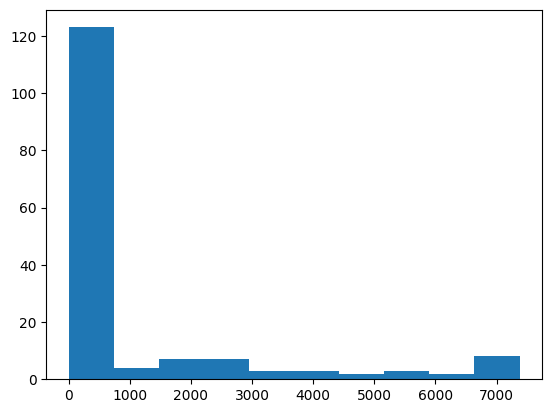

In [24]:
import matplotlib.pyplot as plt

plt.hist(pk_fin_feat.isna().sum(axis=1))
plt.show()

In [25]:
pk_feat_clean = pk_fin_feat.loc[:, pk_fin_feat.isna().sum() <= 30]
pk_feat_clean.shape

(162, 6763)